In [1]:
import random
import matplotlib.pyplot as plt
# Works in Colab (Drive paths) and locally (paths relative to this notebook's folder)
try:
    from google.colab import drive
    IN_COLAB = True
except ImportError:
    IN_COLAB = False
print('Running in Colab' if IN_COLAB else 'Running locally')
import pandas as pd
import numpy as np
from math import radians, cos, sin, asin, sqrt

Running in Colab


In [2]:
if IN_COLAB:
    drive.mount("/content/drive/")

Mounted at /content/drive/


In [3]:
import os, zipfile
if IN_COLAB:
    zipfile.ZipFile("/content/drive/MyDrive/CMPE295ADataset/nyc_output_tabular.zip").extractall("/content/")
elif not os.path.exists("./output/traj_cleaned.parquet") and os.path.exists("./nyc_output_tabular.zip"):
    # locally: put nyc_output_tabular.zip in this folder, it is extracted to ./output/
    zipfile.ZipFile("./nyc_output_tabular.zip").extractall(".")

In [4]:
ROOT_DIR = "/content" if IN_COLAB else "."
# locally: the MAT-Dataset parquet files in URBAN-SYN/data (this notebook is in baselines/diffusion/difftraj/repo/)
DATA_DIR = f"{ROOT_DIR}/output" if IN_COLAB else "../../../../data/nyc_output_tabular/output"
SEED = 101
random.seed(SEED)
rng = np.random.default_rng(SEED)

In [5]:
DATA_SOURCE = "enriched_moves"
MODES = None       # None = all transport modes (team decision); e.g. [2, 3, 6] = bus, car, taxi only
MIN_POINTS = 2     # trajectories with fewer GPS points are dropped

def as_key_str(s):
    # '3', 3 and 3.0 all become '3', so keys match the uid_tid trip_key of the test list
    return s.astype(str).str.replace(r'\.0$', '', regex=True)

if DATA_SOURCE == "enriched_moves":
    df = pd.read_parquet(f"{DATA_DIR}/enriched_moves.parquet").reset_index()   # tid, move_id are the index
    if MODES is not None:
        df = df[df['label'].isin(MODES)].copy()
    # orig_tid = the user's track id: uid + orig_tid is the trip_key used by the test list.
    # tid = one id per move (uid_tid_moveid), so every cell below treats each move as one trajectory.
    df['orig_tid'] = df['tid']
    df['tid'] = as_key_str(df['uid']) + '_' + as_key_str(df['tid']) + '_' + as_key_str(df['move_id'])
elif DATA_SOURCE == "traj_cleaned":
    df = pd.read_parquet(f"{DATA_DIR}/traj_cleaned.parquet")
else:
    raise ValueError(DATA_SOURCE)
df['datetime'] = pd.to_datetime(df['datetime'])
print(f"DATA_SOURCE = {DATA_SOURCE}")
df.head()


DATA_SOURCE = enriched_moves


,tid,move_id,datetime,uid,lat,lng,label,orig_tid
0,3_3_0,0,2021-05-23 08:23:21,3,40.821955,-74.139058,2.0,3
1,3_3_0,0,2021-05-23 08:23:24,3,40.822035,-74.139246,2.0,3
2,3_3_0,0,2021-05-23 08:23:26,3,40.822115,-74.139433,2.0,3
3,3_3_0,0,2021-05-23 08:23:28,3,40.822036,-74.139485,2.0,3
4,3_3_0,0,2021-05-23 08:23:32,3,40.821987,-74.139464,2.0,3


In [6]:
df.shape

(6623956, 8)

In [7]:
print(f'Total number of users: ' + str(len(df['uid'].unique())))
traj_lengths = df.groupby('tid').size()

print(f'Total number of trajectories: {len(traj_lengths)}')
print(f"Trajectories per user: {df.groupby('uid')['tid'].nunique().mean():.2f} on average, "
      f"{(df.groupby('uid')['tid'].nunique() > 1).mean():.1%} of users have more than one")
print(f'Average length: {traj_lengths.mean():.2f} points')
print(f'Shortest trip:  {traj_lengths.min()} points')
print(f'Longest trip:   {traj_lengths.max()} points')

Total number of users: 18762
Total number of trajectories: 19474
Trajectories per user: 1.04 on average, 2.3% of users have more than one
Average length: 340.14 points
Shortest trip:  1 points
Longest trip:   2845 points


In [8]:
longer_than_256 = (traj_lengths > 256).sum()
print(f'\nTrips longer than 256 points: {longer_than_256} ({longer_than_256/len(traj_lengths)*100:.1f}%)')


Trips longer than 256 points: 12078 (62.0%)


In [9]:
df['date'] = df['datetime'].dt.date

# separate the trajectories on different dates
def separate_tids_by_date(df):
    new_df_rows = []

    numeric_tids = pd.to_numeric(df['tid'], errors='coerce')
    new_tid_counter = int(numeric_tids.max()) + 1

    for tid, group_tid in df.groupby('tid'):
        # keep the ORIGINAL tid on every date piece, so uid + orig_tid still matches
        # the trip_key used by the FMM / map-matched files
        group_tid = group_tid.copy()
        group_tid['orig_tid'] = tid
        unique_dates = group_tid['date'].unique()
        if len(unique_dates) > 1:

            unique_dates_sorted = sorted(unique_dates)

            # The first date segment retains the original tid
            first_date = unique_dates_sorted[0]
            first_date_segment = group_tid[group_tid['date'] == first_date].copy()
            first_date_segment['tid'] = tid # Keep original tid for the first segment
            new_df_rows.append(first_date_segment)

            # Subsequent date segments get new tids
            for date in unique_dates_sorted[1:]:
                date_segment = group_tid[group_tid['date'] == date].copy()
                date_segment['tid'] = new_tid_counter
                new_df_rows.append(date_segment)
                new_tid_counter += 1
        else:
            # If trajectory spans only one date, keep its original tid
            single_date_segment = group_tid.copy()
            new_df_rows.append(single_date_segment)

    return pd.concat(new_df_rows)

In [10]:
if DATA_SOURCE == "enriched_moves":
    df_separated = df.copy()   # moves are already single trips between two stops
else:
    df_separated = separate_tids_by_date(df)
print(f'Original number of trajectories: {len(df['tid'].unique())}')
print(f'Number of trajectories after separating by date: {len(df_separated['tid'].unique())}')
df_separated.head()

Original number of trajectories: 19474
Number of trajectories after separating by date: 19474


,tid,move_id,datetime,uid,lat,lng,label,orig_tid,date
0,3_3_0,0,2021-05-23 08:23:21,3,40.821955,-74.139058,2.0,3,2021-05-23
1,3_3_0,0,2021-05-23 08:23:24,3,40.822035,-74.139246,2.0,3,2021-05-23
2,3_3_0,0,2021-05-23 08:23:26,3,40.822115,-74.139433,2.0,3,2021-05-23
3,3_3_0,0,2021-05-23 08:23:28,3,40.822036,-74.139485,2.0,3,2021-05-23
4,3_3_0,0,2021-05-23 08:23:32,3,40.821987,-74.139464,2.0,3,2021-05-23


### Train / test split

Use the **same test trips as Diff-RNTraj**, read from the shared list `fmm_scripts/nyc_test_trips.csv` (`uid`, `tid`; trip_key = `uid_tid`, before the date split). The list is not copied into this folder. In Colab, put a copy of it in the Drive folder.

A trip that was split by date keeps its `orig_tid`, so **every date piece of a test trip goes to the test set**.


In [ ]:
# Shared test list (also used by Diff-RNTraj and prepare_data.py): fmm_scripts/nyc_test_trips.csv
TEST_TRIPS = ("/content/drive/MyDrive/CMPE295ADataset/nyc_test_trips.csv" if IN_COLAB
              else "../../../../fmm_scripts/nyc_test_trips.csv")

def as_key_str(s):
    # '3', 3 and 3.0 all become '3', so the keys match
    return s.astype(str).str.replace(r'\.0$', '', regex=True)

nyc_test = pd.read_csv(TEST_TRIPS, usecols=['uid', 'tid'])
test_keys = set(as_key_str(nyc_test['uid']) + '_' + as_key_str(nyc_test['tid']))

df_separated['trip_key'] = as_key_str(df_separated['uid']) + '_' + as_key_str(df_separated['orig_tid'])
df_separated['split'] = np.where(df_separated['trip_key'].isin(test_keys), 'test', 'train')

found = test_keys & set(df_separated['trip_key'])
print(f"Test trips listed: {len(test_keys)} | found in df_separated: {len(found)}")
if len(found) < len(test_keys):
    print("Not found (dropped during cleaning?):", sorted(test_keys - found)[:10])
print("Trajectories per split (after the date split):")
print(df_separated.groupby('split')['tid'].nunique())


In [12]:
traj_len_separated = df_separated.groupby('tid').size()
print(f'Total number of trajectories: {len(traj_len_separated)}')
print(f'Average length: {traj_len_separated.mean():.2f} points')
print(f'Shortest trip:  {traj_len_separated.min()} points')
print(f'Longest trip:   {traj_len_separated.max()} points')

Total number of trajectories: 19474
Average length: 340.14 points
Shortest trip:  1 points
Longest trip:   2845 points


In [13]:
min_lat = df_separated['lat'].min()
max_lat = df_separated['lat'].max()
min_lng = df_separated['lng'].min()
max_lng = df_separated['lng'].max()

# Grid_size for geographical discretization
# A grid_size of 16x16 gives 256 unique grid IDs (0-255), which fits within nn.Embedding(257, ...)
grid_size = 16

print(f'Latitude range: [{min_lat}, {max_lat}]')
print(f'longitude range: [{min_lng}, {max_lng}]')

Latitude range: [40.4771872, 40.9179995]
longitude range: [-74.2589998, -73.8990007]


In [14]:
def get_grid_id(lat, lng, grid_size=16):
    lat_step = (max_lat - min_lat) / grid_size
    lng_step = (max_lng - min_lng) / grid_size
    x = int((lat - min_lat) / lat_step)
    y = int((lng - min_lng) / lng_step)
    # Clamp values to stay within bounds [0, grid_size-1]
    x = max(0, min(grid_size - 1, x))
    y = max(0, min(grid_size - 1, y))
    return x * grid_size + y

In [15]:
def get_departure_token(dt):
    # Total minutes in 5 minute intervals to fit embedding dimension 288
    return (dt.hour * 60 + dt.minute) // 5

In [16]:
# Calculate categorical departure time IDs and grid IDs for start/end locations
all_start_datetimes = df_separated.groupby('tid')['datetime'].first()
start_time_categorical_ids = all_start_datetimes.apply(get_departure_token)

all_start_grid_ids = df_separated.groupby('tid').apply(lambda x: get_grid_id(x['lat'].iloc[0], x['lng'].iloc[0], grid_size=grid_size), include_groups=False);
all_end_grid_ids = df_separated.groupby('tid').apply(lambda x: get_grid_id(x['lat'].iloc[-1], x['lng'].iloc[-1], grid_size=grid_size), include_groups=False);

# Map these calculated IDs to new columns in df_separated
df_separated['start_time_cat_id'] = df_separated['tid'].map(start_time_categorical_ids)
df_separated['start_grid_id'] = df_separated['tid'].map(all_start_grid_ids)
df_separated['end_grid_id'] = df_separated['tid'].map(all_end_grid_ids)

print('Added start_time_cat_id, start_grid_id, and end_grid_id to df_separated')
df_separated.head()

Added start_time_cat_id, start_grid_id, and end_grid_id to df_separated


,tid,move_id,datetime,uid,lat,lng,label,orig_tid,date,trip_key,split,start_time_cat_id,start_grid_id,end_grid_id
0,3_3_0,0,2021-05-23 08:23:21,3,40.821955,-74.139058,2.0,3,2021-05-23,3_3,train,100,197,182
1,3_3_0,0,2021-05-23 08:23:24,3,40.822035,-74.139246,2.0,3,2021-05-23,3_3,train,100,197,182
2,3_3_0,0,2021-05-23 08:23:26,3,40.822115,-74.139433,2.0,3,2021-05-23,3_3,train,100,197,182
3,3_3_0,0,2021-05-23 08:23:28,3,40.822036,-74.139485,2.0,3,2021-05-23,3_3,train,100,197,182
4,3_3_0,0,2021-05-23 08:23:32,3,40.821987,-74.139464,2.0,3,2021-05-23,3_3,train,100,197,182


In [17]:
def haversine(lat1, lon1, lat2, lon2):
    # Calculate distance between two points in km
    lat1, lon1, lat2, lon2 = map(radians, [lat1, lon1, lat2, lon2])
    dlon, dlat = lon2 - lon1, lat2 - lat1
    a = sin(dlat/2)**2 + cos(lat1) * cos(lat2) * sin(dlon/2)**2
    return 2 * 6371 * asin(sqrt(a))

In [18]:
# Interpolation resampling function from DiffTraj
# - estimates lat/lng values at evenly spaced positions along the original sequence
# x: (N, 2), returns (length, 2)
def resample_trajectory(x, length=200):
    len_x = len(x)
    time_steps = np.arange(length) * (len_x - 1) / (length - 1)
    x = x.T
    resampled_trajectory = np.zeros((2, length))
    for i in range(2):
        resampled_trajectory[i] = np.interp(time_steps, np.arange(len_x), x[i])
    return resampled_trajectory.T

In [19]:
target_len = 256
trajs = []
heads = []
trip_keys = []   # uid_origtid of each row, same order as traj/head
splits = []      # 'train' / 'test'
raw_coords = []  # original (not resampled) lat/lng, same order
traj_ids = []    # trajectory id (enriched_moves: uid_tid_moveid), same order
modes = []       # transport-mode label of the move (NaN for traj_cleaned)
count = 1

for tid, group in df_separated.groupby('tid'):
    if count % 100 == 0:
        print(f'Processing Trajectory no. {count}')
    count += 1

    # skip trips with fewer than MIN_POINTS points
    if len(group) < MIN_POINTS:
        continue

    group = group.sort_values('datetime')

    # Interpolation resampling to target len
    coords = group[['lat', 'lng']].to_numpy(dtype=float)
    final_coords = resample_trajectory(coords, length=target_len)
    final_coords = final_coords.T

    trajs.append(final_coords)
    trip_keys.append(group['trip_key'].iloc[0])
    splits.append(group['split'].iloc[0])
    raw_coords.append(coords)
    traj_ids.append(str(tid))
    modes.append(group['label'].iloc[0] if 'label' in group.columns else np.nan)

    t_start = group['datetime'].iloc[0]
    t_end = group['datetime'].iloc[-1]

    # Convert Duration from Seconds to Minutes
    duration_sec = (t_end - t_start).total_seconds()
    duration_min = duration_sec / 60.0

    # Convert Distance from Kilometers to Meters
    dist_km = sum(haversine(group.iloc[i]['lat'], group.iloc[i]['lng'],
                            group.iloc[i+1]['lat'], group.iloc[i+1]['lng'])
                  for i in range(len(group)-1)) if len(group) > 1 else 0.0
    dist_m = dist_km * 1000.0

    num_pts = len(group)

    # Calculate Average Speed (Meters per Minute)
    avg_speed = (dist_m / duration_min) if duration_min > 0 else 0.0

    # Average distance per point (Meters)
    avg_dist_m = dist_m / (num_pts - 1) if num_pts > 1 else 0.0

    start_time_cat_id = group['start_time_cat_id'].iloc[0]
    start_id_cat = group['start_grid_id'].iloc[0]
    end_id_cat = group['end_grid_id'].iloc[0]

    # [time_id, distance, duration, number of points, avg dist, avg speed, start_grid, end_grid]
    heads.append([
        start_time_cat_id,
        dist_m,
        duration_min,
        num_pts,
        avg_dist_m,
        avg_speed,
        start_id_cat,
        end_id_cat
    ])

traj_tensor = np.stack(trajs)
head_tensor = np.array(heads)
trip_keys = np.array(trip_keys)
traj_ids = np.array(traj_ids)
modes = np.array(modes, dtype=float)
splits = np.array(splits)
train_mask = splits == 'train'
test_mask = splits == 'test'
print(f'train: {train_mask.sum()}  test: {test_mask.sum()}  total: {len(splits)}')


Processing Trajectory no. 100
Processing Trajectory no. 200
Processing Trajectory no. 300
Processing Trajectory no. 400
Processing Trajectory no. 500
Processing Trajectory no. 600
Processing Trajectory no. 700
Processing Trajectory no. 800
Processing Trajectory no. 900
Processing Trajectory no. 1000
Processing Trajectory no. 1100
Processing Trajectory no. 1200
Processing Trajectory no. 1300
Processing Trajectory no. 1400
Processing Trajectory no. 1500
Processing Trajectory no. 1600
Processing Trajectory no. 1700
Processing Trajectory no. 1800
Processing Trajectory no. 1900
Processing Trajectory no. 2000
Processing Trajectory no. 2100
Processing Trajectory no. 2200
Processing Trajectory no. 2300
Processing Trajectory no. 2400
Processing Trajectory no. 2500
Processing Trajectory no. 2600
Processing Trajectory no. 2700
Processing Trajectory no. 2800
Processing Trajectory no. 2900
Processing Trajectory no. 3000
Processing Trajectory no. 3100
Processing Trajectory no. 3200
Processing Trajec

In [20]:
# Normalize traj
# statistics from TRAIN trips only, so nothing about the test set leaks into training
traj_mean = traj_tensor[train_mask].mean(axis=(0, 2))
traj_std = traj_tensor[train_mask].std(axis=(0, 2))

# avoid division by zero
traj_std[traj_std == 0] = 1.0

traj_tensor_norm = traj_tensor.copy()
traj_tensor_norm[:, 0, :] = (traj_tensor[:, 0, :] - traj_mean[0]) / traj_std[0]
traj_tensor_norm[:, 1, :] = (traj_tensor[:, 1, :] - traj_mean[1]) / traj_std[1]


In [21]:
# Normalize head
head_tensor_norm = head_tensor.copy()
# normalize only columns 1:5
# statistics from TRAIN trips only
hmean = head_tensor[train_mask, 1:6].mean(axis=0)
hstd = head_tensor[train_mask, 1:6].std(axis=0)

# avoid divide-by-zero
hstd[hstd == 0] = 1.0

head_tensor_norm[:, 1:6] = (head_tensor[:, 1:6] - hmean) / hstd

hmean = np.array([0, *hmean.tolist()], dtype=np.float32)
hstd = np.array([1, *hstd.tolist()], dtype=np.float32)
len_mean = float(head_tensor[train_mask, 3].mean())
len_std = float(head_tensor[train_mask, 3].std())
if len_std == 0:
    len_std = 1.0

In [22]:
def to_object_array(list_of_arrays):
    out = np.empty(len(list_of_arrays), dtype=object)
    for k, a in enumerate(list_of_arrays):
        out[k] = a
    return out

train_idx, test_idx = np.where(train_mask)[0], np.where(test_mask)[0]

split_files = {
    # main.py trains on traj.npy / head.npy -> TRAIN trips only
    'traj.npy':      traj_tensor_norm[train_idx],
    'head.npy':      head_tensor_norm[train_idx],
    'traj_test.npy': traj_tensor_norm[test_idx],
    'head_test.npy': head_tensor_norm[test_idx],
    # raw real trips in the SAME row order as head*.npy (use these for evaluation)
    'real_trajectories_train.npy': to_object_array([raw_coords[k] for k in train_idx]),
    'real_trajectories_test.npy':  to_object_array([raw_coords[k] for k in test_idx]),
    # uid_origtid of every row, to trace any row back to the original data
    'trip_keys_train.npy': trip_keys[train_idx],
    'trip_keys_test.npy':  trip_keys[test_idx],
    # trajectory id (enriched_moves: uid_tid_moveid) and transport-mode label of every row
    'traj_ids_train.npy': traj_ids[train_idx],
    'traj_ids_test.npy':  traj_ids[test_idx],
    'modes_train.npy': modes[train_idx],
    'modes_test.npy':  modes[test_idx],
}
for name, arr in split_files.items():
    np.save(name, arr, allow_pickle=True)
    print(f'{name:<30} {arr.shape}')


traj.npy                       (15601, 2, 256)
head.npy                       (15601, 8)
traj_test.npy                  (3670, 2, 256)
head_test.npy                  (3670, 8)
real_trajectories_train.npy    (15601,)
real_trajectories_test.npy     (3670,)
trip_keys_train.npy            (15601,)
trip_keys_test.npy             (3670,)
traj_ids_train.npy             (15601,)
traj_ids_test.npy              (3670,)
modes_train.npy                (15601,)
modes_test.npy                 (3670,)


In [23]:
save_path = '/content/drive/MyDrive/CMPE295ADataset/' if IN_COLAB else './'

for name, arr in split_files.items():
    np.save(save_path + name, arr, allow_pickle=True)


In [24]:
print(f'All trips:   {traj_tensor_norm.shape}')
print(f'Train trips: {traj_tensor_norm[train_idx].shape}')
print(f'Test trips:  {traj_tensor_norm[test_idx].shape}')
# sanity checks: no trip_key in both splits; report test trips dropped for having < 2 points
assert not set(trip_keys[train_idx]) & set(trip_keys[test_idx])
dropped = found - set(trip_keys[test_idx])
if dropped:
    print(f"{len(dropped)} test trips were dropped (fewer than 2 points):", sorted(dropped)[:10])


All trips:   (19271, 2, 256)
Train trips: (15601, 2, 256)
Test trips:  (3670, 2, 256)


In [25]:
head_data = np.load('head.npy')
print('Max Start ID:', head_data[:, 6].max())
print('Max End ID:', head_data[:, 7].max())

Max Start ID: 253.0
Max End ID: 253.0


In [26]:
# TRAIN-only statistics: copy these into Traj_Generation.ipynb (cell 6)
print(f'hmean={hmean.tolist()}')
print(f'hstd={hstd.tolist()}')
print(f'len_mean={len_mean}')
print(f'len_std={len_std}')

hmean=[0.0, 6697.8759765625, 12.251601219177246, 342.8433532714844, 19.023038864135742, 645.09619140625]
hstd=[1.0, 5227.43212890625, 28.54372215270996, 180.35935974121094, 64.89196014404297, 499.4714050292969]
len_mean=342.84334337542464
len_std=180.35935703150173


In [27]:
# Global traj mean and std for lat and lng
print(f"traj_mean={traj_mean.tolist()}")
print(f"traj_std={traj_std.tolist()}")

traj_mean=[40.69391411557421, -74.0459727949714]
traj_std=[0.09492396610019764, 0.0881728854641001]


In [28]:
def plot_traj(df, grid_size=16):
    min_lat, max_lat = df['lat'].min(), df['lat'].max()
    min_lng, max_lng = df['lng'].min(), df['lng'].max()

    # 2. Add a tiny buffer so edge points clearly sit inside a box
    buffer = 0.005
    lat_range = np.linspace(min_lat - buffer, max_lat + buffer, grid_size + 1)
    lng_range = np.linspace(min_lng - buffer, max_lng + buffer, grid_size + 1)

    plt.figure(figsize=(10, 10))

    # 3. Draw the grid lines
    for lat in lat_range:
        plt.axhline(y=lat, color='gray', linestyle='--', alpha=0.3)
    for lng in lng_range:
        plt.axvline(x=lng, color='gray', linestyle='--', alpha=0.3)

    # 4. Plot the trajectory path
    plt.plot(df['lng'], df['lat'], marker=None, color='blue', label='Trip Path', alpha=0.7)

    # 5. Highlight Start and End points
    plt.scatter(df['lng'].iloc[0], df['lat'].iloc[0], color='green', s=100, label='Start')
    plt.scatter(df['lng'].iloc[-1], df['lat'].iloc[-1], color='red', s=100, label='End')

    plt.title(f"Trajectory Visualization on {grid_size}x{grid_size} Grid")
    plt.xlabel("Longitude")
    plt.ylabel("Latitude")
    plt.legend()
    plt.show()


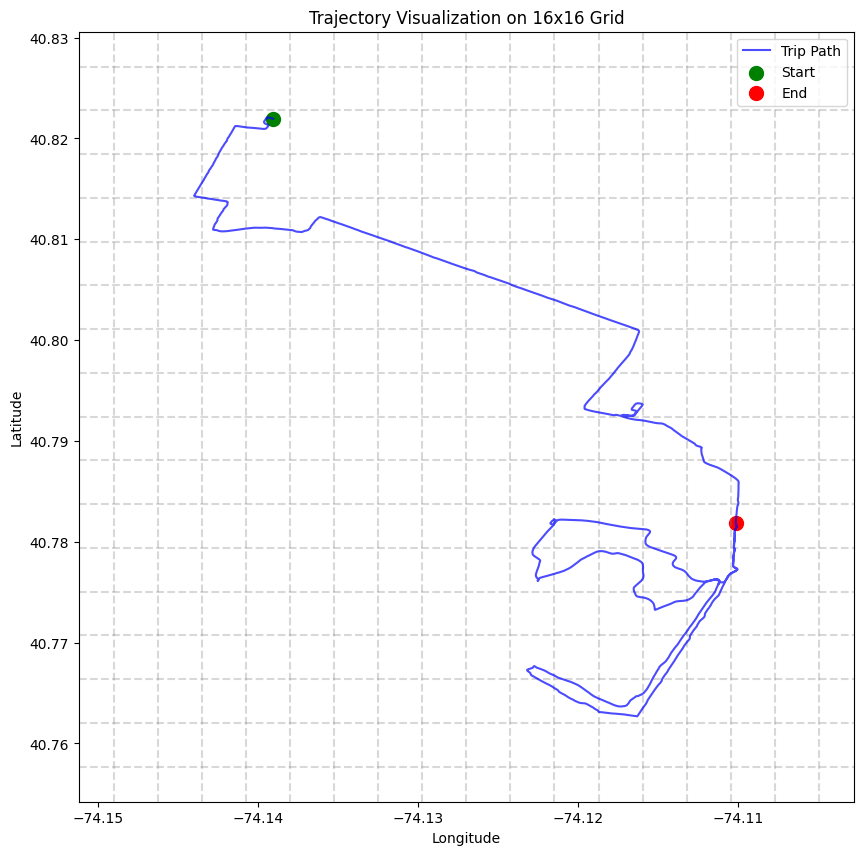

In [29]:
test_traj = df_separated[df_separated['tid'] == df_separated['tid'].iloc[0]].sort_values('datetime')
plot_traj(test_traj)

In [30]:
def plot_grid_from_df(df, grid_size=16, buffer=0.005):

    df = df.dropna(subset=['lat', 'lng', 'tid']).copy()

    min_lat, max_lat = df['lat'].min(), df['lat'].max()
    min_lng, max_lng = df['lng'].min(), df['lng'].max()

    lat_range = np.linspace(min_lat - buffer, max_lat + buffer, grid_size + 1)
    lng_range = np.linspace(min_lng - buffer, max_lng + buffer, grid_size + 1)

    fig, ax = plt.subplots(figsize=(10, 10))

    for lat in lat_range:
        ax.axhline(y=lat, color='gray', linestyle='--', alpha=0.3)
    for lng in lng_range:
        ax.axvline(x=lng, color='gray', linestyle='--', alpha=0.3)

    for trip_id, trip_df in df.groupby('tid'):
        trip_df = trip_df.sort_index()

        ax.plot(trip_df['lng'], trip_df['lat'], alpha=0.3, color='blue')
        # ax.scatter(trip_df['lng'].iloc[0], trip_df['lat'].iloc[0], color='green', s=50)
        # ax.scatter(trip_df['lng'].iloc[-1], trip_df['lat'].iloc[-1], color='red', s=50)

    ax.set_title(f"Trajectory Visualization on {grid_size}x{grid_size} Grid")
    ax.set_xlabel("Longitude")
    ax.set_ylabel("Latitude")
    ax.set_aspect('equal', adjustable='box')

    plt.show()

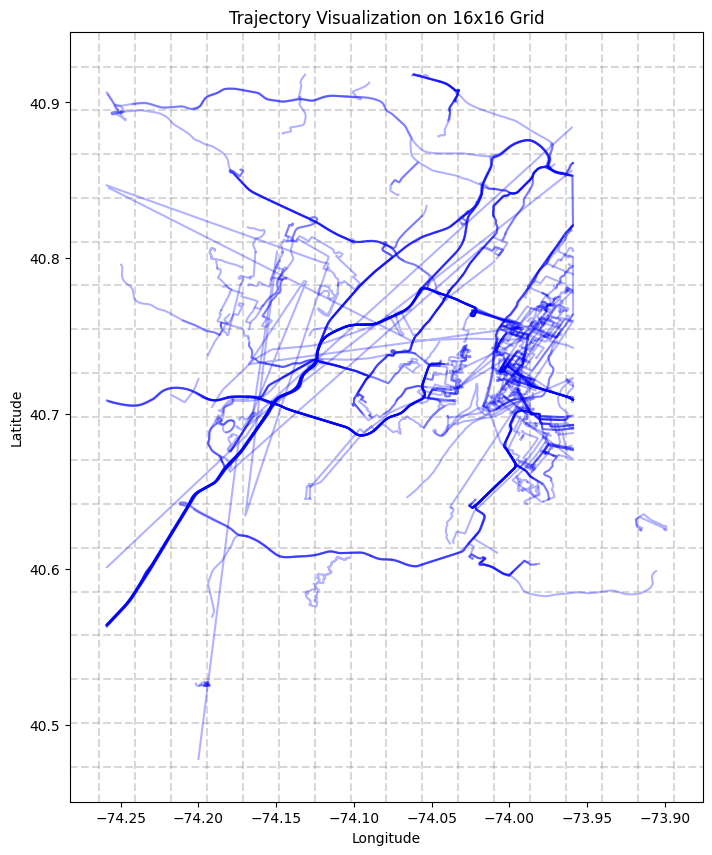

In [31]:
# first 500
first_500_tid = df_separated['tid'].unique()[:500]
test_trajs = df_separated[df_separated['tid'].isin(first_500_tid)]
plot_grid_from_df(test_trajs)

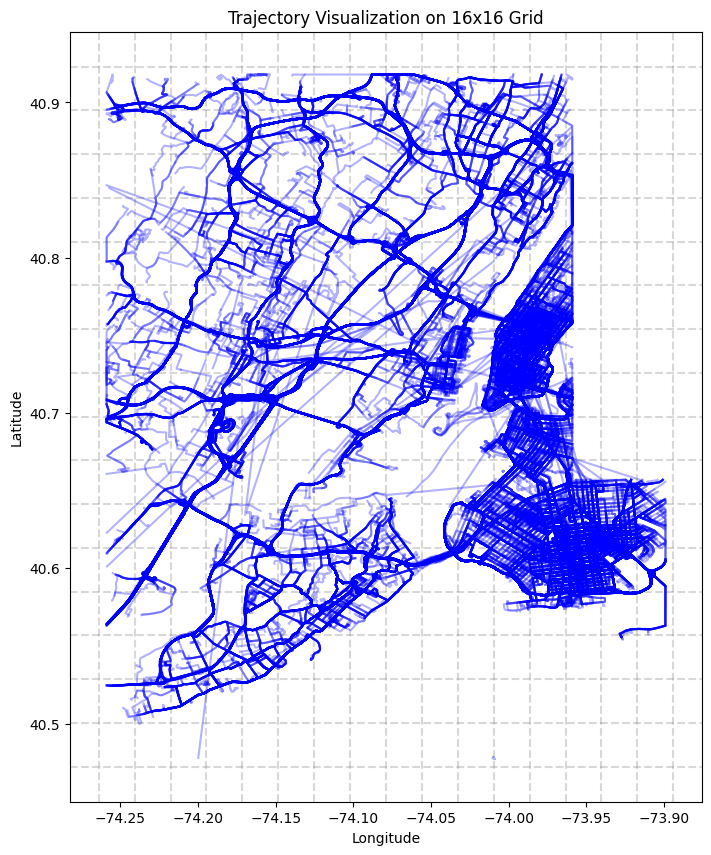

In [32]:
all_tid = df_separated['tid'].unique()
test_full_traj = df_separated[df_separated['tid'].isin(all_tid)]
plot_grid_from_df(test_full_traj)

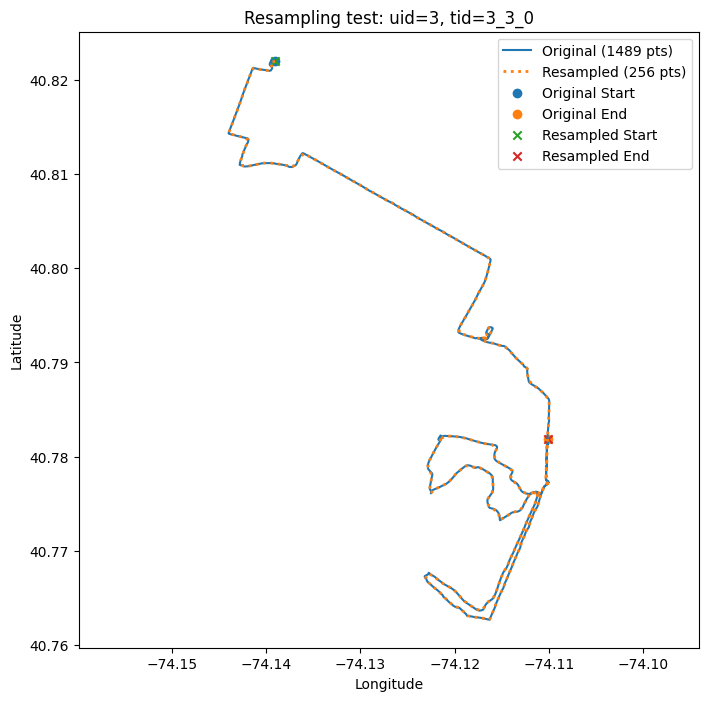

In [33]:
# Test resampling on the first trajectory
uid_test = df_separated['uid'].iloc[0]
tid_test = df_separated['tid'].iloc[0]

group = (
    df_separated[
        (df_separated["uid"] == uid_test) &
        (df_separated["tid"] == tid_test)
    ]
    .sort_values("datetime")
    .reset_index(drop=True)
)
coords = group[["lat", "lng"]].to_numpy(dtype=float)
resampled = resample_trajectory(coords, length=256)
plt.figure(figsize=(8, 8))
plt.plot(coords[:, 1], coords[:, 0], label=f"Original ({len(coords)} pts)")
plt.plot(resampled[:, 1], resampled[:, 0], linestyle=":", linewidth=2,
         label=f"Resampled ({len(resampled)} pts)")
plt.scatter(coords[0, 1], coords[0, 0], label="Original Start")
plt.scatter(coords[-1, 1], coords[-1, 0], label="Original End")
plt.scatter(resampled[0, 1], resampled[0, 0], marker="x", label="Resampled Start")
plt.scatter(resampled[-1, 1], resampled[-1, 0], marker="x", label="Resampled End")
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.title(f"Resampling test: uid={uid_test}, tid={tid_test}")
plt.legend()
plt.axis("equal")
plt.show()

In [34]:
# save trajectories as npy file for evaluation
target_n = 500
real_trajs = []
kept_keys = []

for (uid, tid), group in df_separated.groupby(["uid", "tid"]):
    group = group.sort_values("datetime").reset_index(drop=True)

    coords = group[["lat", "lng"]].to_numpy(dtype=float)

    if len(coords) < 2:
        continue

    real_trajs.append(coords)
    kept_keys.append((uid, tid))

    if len(real_trajs) == target_n:
        break

real_trajs = np.array(real_trajs, dtype=object)
file_name = "real_trajectories_" + str(target_n) + ".npy"
np.save(file_name, real_trajs, allow_pickle=True)
np.save(save_path + file_name, real_trajs)

print("Number of real trajectories:", len(real_trajs))

Number of real trajectories: 500


In [35]:
# save the whole thing (ALL trips, grouped by (uid, tid))
# NOTE: this order does NOT match head.npy / traj.npy, and it mixes train and test.
# For evaluation use real_trajectories_train.npy / real_trajectories_test.npy instead.
real_trajs = []

for (uid, tid), group in df_separated.groupby(["uid", "tid"]):
    group = group.sort_values("datetime").reset_index(drop=True)
    coords = group[["lat", "lng"]].to_numpy(dtype=float)
    if len(coords) < 2:
        continue
    real_trajs.append(coords)

real_trajs = np.array(real_trajs, dtype=object)
file_name = "full_real_trajectories.npy"

np.save(file_name, real_trajs, allow_pickle=True)
np.save(save_path + file_name, real_trajs, allow_pickle=True)

print(f"Saved {len(real_trajs)} real trajectories")

Saved 19271 real trajectories


In [36]:
real_trajs = [
    group.sort_values('datetime')[['lat', 'lng']].to_numpy()
    for _, group in df_separated.groupby('tid')
    if len(group) >= 2
]

np.save(save_path + 'real_trajs.npy', np.array(real_trajs, dtype=object), allow_pickle=True)

In [37]:
np.save(save_path + 'traj_stats.npy', {
    'mean': traj_mean,          # shape (2,) — [lat_mean, lng_mean]
    'std':  traj_std,           # shape (2,)
    'hmean': hmean,             # shape (6,)
    'hstd':  hstd,              # shape (6,)
    'len_mean': len_mean,
    'len_std':  len_std,
})